# Hillview Harmony: Business Analytics model

**MQBS3010 Capstone, Group 1I, Macquarie University (2026)**  |  Author: Quang, N. (Business Analytics)  |  Client: The King's Foundation (SDG 11)

This notebook is the complete analysis behind **Chapter 4: Business Analytics**. It rebuilds Finance's cost model in Python, then runs the scenarios, sensitivity tests, Monte Carlo simulation and recommendation tests quoted in the chapter, and draws **Figures 4.1 to 4.6**. Every number in the chapter can be traced to a cell below (see Section 9, the *chapter check*).

## How to read this notebook
Each section starts with a short note on **what it does and why**, followed by the code and its output. The code is stored with its results, so you can read it without running anything.

| Section | What it does | Feeds |
|---|---|---|
| 1. Setup | Libraries and plotting style | - |
| 2. Finance's cost model | Rebuilds Finance's cost engine from the FINAL workbooks (Drake, 2026a, 2026b) and checks it against Finance's Year 5 surplus | All sections |
| 3. Benchmark growth | Growth range from the two comparable operators | Figures 4.1, 4.5 |
| 4. Scenarios | Low, Base and High projections of school student-days, surplus and return | Figures 4.1, 4.2 |
| 5. Sensitivity | One input at a time around Finance's plan | Figure 4.3 |
| 6. Monte Carlo | 10,000 futures with every input varying together | Figure 4.4 |
| 7. Recommendation tests | Cost of heritage and access commitments | Figure 4.6 |
| 8. Figures | Draws Figures 4.1 to 4.6 | Chapter 4 |

## How to run it
Python 3.9 or later with `numpy` and `matplotlib` only. **Run all cells top to bottom (about one minute).** No data files are needed: Finance's inputs are typed into Section 2 with their source. The simulations use a fixed random seed (42), so the results are identical on every run.

## Key terms
- **Student-day**: one school student attending for one day. Overnight camps count as a student for each day.
- **Year 5 surplus**: Year 5 operating surplus after depreciation, including the surplus-funded conservation set aside under Finance's reinvestment policy.
- **Hurdle**: the Foundation's required return of 3% on the $1 million endowment, which equals a **$30,000** Year 5 surplus. Finance also reports return on average investment (a lower surplus bar of about $13,100); this notebook reports both and the chapter uses $30,000.
- **ARR (conservative)**: Year 5 surplus divided by the $1 million endowment (Drake, 2026b).
- **Low, Base, High**: launch of 50, 72 and 90 students per overnight camp (69%, 100% and 125% of Finance's launch volume), combined with the lowest, mean and highest benchmark growth rates.

## 1. Setup
Imports and the plotting style used for every figure. The chapter figures use a white background and the King's Foundation colour palette. They carry no title inside the image because each figure's heading is typed in the Word chapter.

In [1]:
import sys, itertools, numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from matplotlib.patches import Patch, Rectangle

from matplotlib import font_manager as fm
_have = {f.name for f in fm.fontManager.ttflist}
FONT = next((f for f in ('Arial', 'Liberation Sans', 'Helvetica', 'DejaVu Sans') if f in _have), 'DejaVu Sans')   # Arial if installed
plt.rcParams.update({'text.parse_math': False, 'font.family': FONT, 'font.size': 10,
                     'axes.edgecolor': '#c9c8c3', 'axes.labelcolor': '#52514e', 'xtick.color': '#52514e', 'ytick.color': '#52514e',
                     'figure.facecolor': '#ffffff', 'axes.facecolor': '#ffffff', 'savefig.facecolor': '#ffffff'})
INK, INK2 = '#0b0b0b', '#52514e'
# King's Foundation palette (from the team presentation): dark green, sage, sand, deep red
COL = {'Base': '#00330C', 'Low': '#980000', 'High': '#789D64', 'Finance plan': '#B39D74'}
usd = FuncFormatter(lambda v, p: f"-${abs(v)/1000:,.0f}k" if v < 0 else f"${v/1000:,.0f}k")
def clean(ax):
    for s in ('top', 'right'): ax.spines[s].set_visible(False)
    ax.grid(axis='y', color='#e6e5e1', lw=0.6); ax.set_axisbelow(True)
# The Word chapter carries each figure's heading and source, so the images have no in-image title or source line.
def title(fig, t, sub): pass
def src(fig, s): pass

# The cost-model functions below live in this notebook; "m" and "T" are aliases so the code reads like the original modules.
m = T = sys.modules['__main__']

## 2. Finance's cost model

**What it does.** Rebuilds Finance's cost engine so that any scenario can be re-run. Given a path of school student-days (Years 1 to 5) and optional changes to price and cost lines, `run()` returns revenue, costs, surplus before and after depreciation, and the surplus after Finance's reinvestment policy (50% of surplus reinvested in conservation from Year 3).

**Why.** Finance's workbook gives one plan. To ask "what if volume is lower?" or "how likely is a surplus above the hurdle?", we need the same arithmetic in code so it can be repeated thousands of times.

**Inputs.** Every constant below is copied from Finance's FINAL workbooks: Drake (2026a) *cost structure and break-even* and Drake (2026b) *performance and returns*. The comments name each source line. Rows marked *Low reliability* are Finance's own reliability ratings, and they set how wide we make each input in the sensitivity and Monte Carlo sections.

### 2.1 Inputs from Finance's workbooks

In [2]:
# ---------------- Inputs taken directly from Finance's workbooks ----------------
YEARS = [1, 2, 3, 4, 5]
# School student-days in Finance's plan (Y1..Y5) and the mix between day / residential
PLAN_SD   = np.array([0, 9720, 10692, 11745, 12897], float)
DAY_SD    = np.array([0, 3240, 3321, 3402, 3474], float)
RES_SD    = np.array([0, 6480, 7371, 8343, 9423], float)
RES_NIGHT = np.array([0, 4320, 4914, 5562, 6282], float)
PROG_DAYS = np.array([0, 72, 81.9, 92.7, 104.7], float)       # 'cycles' run
DRY_HIRE  = np.array([0, 12, 27, 0, 0], float)                # room-days (Low reliability)
WET_HIRE  = np.array([0, 0, 0, 36, 45], float)                # room-days (Low reliability)

DAY_PRICE = 98.602898     # $/student-day  (cost-plus, Pricing tab, FINAL)
RES_PRICE = 172.142983      # $/student-night
DRY_RATE  = 700.0         # $/room-day
WET_PRICE = 11306.6667    # $/room-day
WET_COST  = 9476.0        # bought-in services per wet-hire room-day

CONTRACT_PER_CYCLE = 3955.0       # SRAC 2640 + ceramics 987 + horticulturist 328
CATERING_PER_NIGHT = 21.33
SUPPLIES_PER_SD    = 1.65414 + 5.0  # workshop + market-garden supplies
PAY_FEE            = 0.02         # % of total revenue
CORE_STAFF  = np.array([102492.613, 310902.953, 310902.953, 310902.953, 310902.953])  # Site Manager + 3 General Supervisors (FINAL)
OTHER_FIXED = np.array([164443, 229443, 234147, 256121, 257171], float)
UTILITIES   = 80000.0             # inside OTHER_FIXED (Low reliability)
MAINTENANCE = 20000.0             # inside OTHER_FIXED (Low reliability)
MARKETING   = np.array([0, 65000, 65000, 65000, 65000], float)  # inside OTHER_FIXED
DEPREC      = np.array([57880, 57880, 65025, 51099, 51099], float)

CAPEX, SETUP = 452583.19, 89500.0
OP_FUNDING_Y1, WORKING_CAP = 266935.613, 55664.972
ENDOWMENT = 1_000_000.0
AVG_INVEST = 281956.567           # 2.2 ARR Base B8 (capex/2 + working capital); 2.5 adds reinvestment/2
HURDLE, TARGET = 0.03, 0.035
# ---- Section 2.5 layer (Performance and Returns FINAL): reinvestment funded from operating surplus ----
WET_EQUIP_Y3 = 35727.0            # capex, already depreciated inside the 2.4 DEPREC line
RESTORATION  = 100000.0           # Year 3 heritage restoration, 25-yr life, NOT in 2.4 depreciation
CMP_Y3       = 57500.0            # Year 3 conservation management plan, expensed
POLICY_SHARE, POLICY_START, POLICY_LIFE = 0.5, 3, 25   # 50% of surplus reinvested in conservation from Year 3 (capex)
CAPACITY_SD = 270 * 250           # 67,500 student-days (Assumptions C26*C27)
SPC_PLAN = np.where(PROG_DAYS > 0, PLAN_SD / np.where(PROG_DAYS > 0, PROG_DAYS, 1), 0)  # students per cycle

DAY_SHARE = np.where(PLAN_SD > 0, DAY_SD / np.where(PLAN_SD > 0, PLAN_SD, 1), 0)
NIGHT_PER_RES_SD = 2.0 / 3.0      # 3 days / 2 nights camp

### 2.2 The scenario engine: `run()`
`run()` works in four steps: (1) split school student-days into day and overnight programs, (2) price them and add room-hire revenue, (3) add fixed and variable costs (contractors per program day, catering per night, staff, utilities, maintenance, marketing), (4) apply Finance's Section 2.5 layer: the Year 3 restoration and conservation plan, and 50% of surplus reinvested in conservation from Year 3. Each keyword argument is a multiplier (for example `price=0.9` is a 10% lower price), which is how the sensitivity and simulation sections change one assumption at a time.

In [3]:
def run(sd=None, price=1.0, contractor=1.0, wet=1.0, utilities=1.0, staff=1.0,
        catering=1.0, maint=1.0, marketing=1.0, extra_fixed=0.0, day_price=None, policy=True, pol_share=None):
    """Return dict of yearly arrays. `sd` = school student-days by year (Y1..Y5); default = Finance's plan."""
    sd = PLAN_SD.copy() if sd is None else np.asarray(sd, float)
    day = sd * DAY_SHARE
    res = sd - day
    nights = res * NIGHT_PER_RES_SD
    cycles = np.where(sd > 0, sd / np.where(SPC_PLAN > 0, SPC_PLAN, 1), 0)
    wet_rd = WET_HIRE * wet
    dp = DAY_PRICE if day_price is None else day_price
    rev_school = (day * dp + nights * RES_PRICE) * price
    rev_dry = DRY_HIRE * DRY_RATE
    rev_wet = wet_rd * WET_PRICE
    revenue = rev_school + rev_dry + rev_wet
    fixed = (CORE_STAFF * staff
             + OTHER_FIXED
             + UTILITIES * (utilities - 1) * (YEARS_ARR > 0)
             + MAINTENANCE * (maint - 1) * (YEARS_ARR > 0)
             + MARKETING * (marketing - 1)
             + extra_fixed * (YEARS_ARR > 1))
    var = (cycles * CONTRACT_PER_CYCLE * contractor
           + nights * CATERING_PER_NIGHT * catering
           + sd * SUPPLIES_PER_SD
           + revenue * PAY_FEE
           + wet_rd * WET_COST)
    opcost = fixed + var
    surplus_pre = revenue - opcost                       # cash surplus before depreciation (2.4 row 46)
    surplus24 = surplus_pre - DEPREC                     # 2.4 'operating surplus after depreciation'
    # --- Section 2.5 layer ---
    dep_rest = np.where(YEARS_ARR >= 3, RESTORATION / 25.0, 0.0)
    cmp_ = np.where(YEARS_ARR == 3, CMP_Y3, 0.0)
    pshare = POLICY_SHARE if pol_share is None else pol_share
    pol_capex = np.zeros(5); pol_dep_cum = 0.0; surplus = np.zeros(5)
    for t in range(5):
        base = surplus24[t] - dep_rest[t] - cmp_[t] - pol_dep_cum
        if policy and (t + 1) >= POLICY_START and base > 0:
            pol_capex[t] = pshare * base
        pol_dep_cum += pol_capex[t] / POLICY_LIFE
        surplus[t] = base - pol_capex[t] / POLICY_LIFE
    reinvest = np.zeros(5); reinvest[2] += WET_EQUIP_Y3 + RESTORATION
    reinvest = reinvest + pol_capex
    return dict(sd=sd, revenue=revenue, rev_school=rev_school, rev_wet=rev_wet, fixed=fixed, var=var,
                opcost=opcost, surplus_pre=surplus_pre, surplus24=surplus24, surplus=surplus,
                cmp=cmp_, reinvest=reinvest, pol_capex=pol_capex, cycles=cycles, contrib_sd=None)
YEARS_ARR = np.array(YEARS)

### 2.3 Returns, cash and the Finance check
`metrics()` turns a run into the measures used in the chapter: Year 5 surplus, ARR on the endowment (conservative) and on average investment (Finance's headline), NPV, payback and the lowest year-end cash balance (the cash test in Finance's Section 2.5).

**Check.** The run with no changes must reproduce Finance's Year 5 operating surplus of **$203,657** (Drake, 2026b). If it does, every difference between our scenarios and Finance's plan comes from the assumptions we change, not from a rebuilding error.

In [4]:
def cash_flows(r, horizon=10):
    """Cash flows t0..t(horizon). t0 = capex + set-up. Y1 = set-up-year loss + working capital.
    Y2-Y5 = cash surplus (before depreciation) less the Year 3 conservation plan and reinvestment capex (2.5 layer).
    Y6+ (used only to date payback) = Year 5 cash surplus held flat, no further reinvestment.
    Working capital recovered at the end of the horizon."""
    sp = r['surplus_pre'] - r['cmp'] - r['reinvest']
    cf = [-(CAPEX + SETUP), sp[0] - WORKING_CAP] + list(sp[1:])
    while len(cf) < horizon + 1:
        cf.append(r['surplus_pre'][-1])
    cf[-1] += WORKING_CAP
    return np.array(cf[:horizon + 1])

def npv(rate, cf):
    return float(sum(c / (1 + rate) ** i for i, c in enumerate(cf)))

def irr(cf):
    lo, hi = -0.99, 2.0
    if npv(lo, cf) * npv(hi, cf) > 0:
        return float('nan')
    for _ in range(200):
        m = (lo + hi) / 2
        if npv(m, cf) > 0: lo = m
        else: hi = m
    return m

def den5(r):
    """2.5 ARR denominator at Year 5: 2.2 average investment + (cost)/2 of each surplus-funded capex item."""
    return AVG_INVEST + (WET_EQUIP_Y3 + RESTORATION + r['pol_capex'].sum()) / 2.0

def metrics(r):
    s = r['surplus']
    cf10 = cash_flows(r, 10); cf5 = cf10[:6]   # 5-year view: no terminal value, no working-capital recovery
    cum = np.cumsum(cf10)
    pay = next((i for i, c in enumerate(cum) if c >= 0), None)
    return dict(
        y5_surplus=float(s[4]), y5_revenue=float(r['revenue'][4]),
        arr_headline=float(s[4] / den5(r)),               # 2.5 definition: Y5 operating surplus / (average investment + reinvestment/2)
        arr_conservative=float(s[4] / ENDOWMENT),         # Y5 surplus / $1m
        arr_5yr_avg_endow=float(s.mean() / ENDOWMENT),    # average surplus Y1-5 incl. set-up loss / $1m
        arr_5yr_avg_inv=float(s.mean() / den5(r)),
        arr_24_headline=float(r['surplus24'][4] / AVG_INVEST),   # 2.2 ARR Base (before 2.5 reinvestment layer)
        npv5_3=npv(0.03, cf5), npv10_3=npv(0.03, cf10), npv10_35=npv(0.035, cf10),
        irr10=irr(cf10), payback_year=pay,
        cost_ratio_y5=float((r['opcost'][4] + DEPREC[4]) / r['revenue'][4]),
        den5=float(den5(r)), min_cash=float(min_cash(r)))

def min_cash(r):
    """2.5 cash test: endowment less launch spending, plus cash surplus less reinvestment; lowest year-end balance."""
    bal = ENDOWMENT - (CAPEX + SETUP); lo = 1e18
    for t in range(5):
        bal += r['surplus_pre'][t] - r['cmp'][t] - r['reinvest'][t]; lo = min(lo, bal)
    return lo

def breakeven_sd(r_year5_kwargs=None, target_surplus=0.0):
    """Student-days needed in Y5 for Y5 surplus (after dep, wet-hire included) = target. Bisection."""
    kw = r_year5_kwargs or {}
    lo, hi = 0.0, 67500.0
    for _ in range(80):
        m = (lo + hi) / 2
        sd = PLAN_SD.copy(); sd[4] = m
        if run(sd, **kw)['surplus'][4] > target_surplus: hi = m
        else: lo = m
    return hi

In [5]:
FINANCE_Y5_SURPLUS = 203657.0      # Drake (2026b), Calculations sheet, Year 5 operating surplus
plan = run()
print(f"Finance plan, Year 5 surplus rebuilt in Python : ${plan['surplus'][4]:,.2f}")
print(f"Finance's reported figure                      : ${FINANCE_Y5_SURPLUS:,.2f}")
print(f"Difference                                     : ${plan['surplus'][4]-FINANCE_Y5_SURPLUS:,.2f}   (within $1: {'OK' if abs(plan['surplus'][4]-FINANCE_Y5_SURPLUS) < 1 else 'CHECK'})")

Finance plan, Year 5 surplus rebuilt in Python : $203,657.10
Finance's reported figure                      : $203,657.00
Difference                                     : $0.10   (within $1: OK)


## 3. Benchmark growth

**What it does.** Calculates year-on-year revenue growth from the published accounts of the two comparable operators: Crusader Union (FY2023-24 to FY2024-25, excluding capital-campaign donations) and YMCA Camping (FY2023 to FY2024 and FY2024 to FY2025). Hillview has no booking history, so these three observations give the **lowest (4.8%), mean (6.7%) and highest (8.5%)** growth rates used for Low, Base and High.

**Why.** Growth is the only input the team has to estimate from outside Finance's workbooks. Section 3 of the chapter explains why the range is a judgment, not a confidence interval.

In [6]:
OUT = {}   # results are collected here and used by the figure and check sections
# Year-on-year revenue growth of the two operators (Crusader Union 2025; YMCA Camping Ltd 2024, 2025)
GROWTH_OBS = {"Crusader Union FY23/24-24/25 (excl. capital campaign)": 18249398/16813900-1,
              "YMCA Camping FY23-24": 19825707/18921663-1, "YMCA Camping FY24-25": 21166872/19825707-1}
g_low, g_high = min(GROWTH_OBS.values()), max(GROWTH_OBS.values())
g_mean, g_med = float(np.mean(list(GROWTH_OBS.values()))), float(np.median(list(GROWTH_OBS.values())))
OUT['growth_obs'] = GROWTH_OBS
OUT['growth'] = dict(low=g_low, mean=g_mean, median=g_med, high=g_high)

# Finance's implied growth in school student-days
OUT['finance_growth'] = [float(m.PLAN_SD[i]/m.PLAN_SD[i-1]-1) for i in (2, 3, 4)]

In [7]:
print("Year-on-year revenue growth observations")
for k, v in GROWTH_OBS.items(): print(f"  {k:<58s} {v*100:5.1f}%")
print(f"\nMinimum / mean / maximum: {g_low*100:.1f}% / {g_mean*100:.1f}% / {g_high*100:.1f}%   (used for Low / Base / High)")
print("Finance's own implied growth in school student-days, Years 3-5:", [f"{x*100:.1f}%" for x in OUT['finance_growth']])

Year-on-year revenue growth observations
  Crusader Union FY23/24-24/25 (excl. capital campaign)        8.5%
  YMCA Camping FY23-24                                         4.8%
  YMCA Camping FY24-25                                         6.8%

Minimum / mean / maximum: 4.8% / 6.7% / 8.5%   (used for Low / Base / High)
Finance's own implied growth in school student-days, Years 3-5: ['10.0%', '9.8%', '9.8%']


## 4. Scenarios: Low, Base and High

**What it does.** Projects school student-days in two steps: a **launch volume in Year 2** (Finance's 9,720 student-days scaled to 69%, 100% or 125%, which matches overnight groups of 50, 72 and 90 students) and then **growth at the benchmark rate** to Year 5. Each path is run through the cost model above.

**Why.** The launch year decides which side of break-even Hillview lands on, so the scenarios vary launch and growth together. Finance's plan is run alongside for comparison. `BE_ACC` is Finance's accounting break-even for schools only (Drake, 2026a, Break-Even sheet).

In [8]:
# Scenario paths and results
LAUNCH = dict(Low=50/72, Base=1.0, High=90/72)   # Low 50, Base 72, High 90 = Finance maximum students
GROW = dict(Low=g_low, Base=g_mean, High=g_high)
def path(launch, g):
    sd = np.zeros(5); sd[1] = m.PLAN_SD[1]*launch
    for t in (2, 3, 4): sd[t] = sd[t-1]*(1+g)
    return sd
SCEN = {k: path(LAUNCH[k], GROW[k]) for k in LAUNCH}
SCEN['Finance plan'] = m.PLAN_SD.copy()
BE_ACC = [None, 9687, 10035, 10318, 10486]      # Finance's FINAL Break-Even tab, block B (schools only, accounting)
res = {}
for k, sd in SCEN.items():
    r = m.run(sd); mt = m.metrics(r)
    mt.update(sd=[float(x) for x in sd], occupancy=[float(x/m.CAPACITY_SD) for x in sd],
              revenue=[float(x) for x in r['revenue']], surplus=[float(x) for x in r['surplus']],
              surplus_pre=[float(x) for x in r['surplus_pre']], cycles=[float(x) for x in r['cycles']])
    res[k] = mt
OUT['scenarios'] = res
OUT['launch'] = LAUNCH; OUT['grow'] = GROW

In [9]:
print(f"{'Scenario':<14s}{'Y5 student-days':>16s}{'Y5 surplus':>13s}{'ARR (endowment)':>17s}{'ARR (avg. inv.)':>17s}{'Lowest cash':>14s}")
for k in ('Low', 'Base', 'Finance plan', 'High'):
    s = OUT['scenarios'][k]
    print(f"{k:<14s}{s['sd'][4]:>16,.0f}{s['y5_surplus']:>13,.0f}{s['arr_conservative']*100:>16.1f}%{s['arr_headline']*100:>16.1f}%{s['min_cash']:>14,.0f}")
print(f"\nAccounting break-even, Year 5: {BE_ACC[4]:,} student-days.   Hurdle: 3% of $1m = ${0.03*ENDOWMENT:,.0f} (Year 5 surplus).")

Scenario       Y5 student-days   Y5 surplus  ARR (endowment)  ARR (avg. inv.)   Lowest cash
Low                      7,764      -92,477            -9.2%           -26.4%      -316,735
Base                    11,805      141,283            14.1%            34.4%       169,884
Finance plan            12,897      203,657            20.4%            46.6%       189,424
High                    15,535      350,455            35.0%            63.8%       190,981

Accounting break-even, Year 5: 10,486 student-days.   Hurdle: 3% of $1m = $30,000 (Year 5 surplus).


## 5. One-at-a-time sensitivity

**What it does.** Moves one input at a time around **Finance's plan** (not our Base case) and records Year 5 surplus. Each input has a low and a high case set from Finance's reliability ratings: school volume ±20%, price ±10%, contractor day rates ±25%, core staff ±20%, wet-hire volume 0% to 150%, utilities ±50%, catering ±20%, heritage maintenance ×0.5 to ×3, marketing ±30%. For each input it also solves for the **threshold multiplier** at which Year 5 surplus falls to the $30,000 hurdle (`hurdle_conservative`).

**Why.** It shows which assumptions matter most and how far each can move before the hurdle is missed. In the chapter, volume (threshold 0.76) and price (0.87) dominate.

In [10]:
# Sensitivity around Finance's plan
base = m.run(); base_y5 = float(base['surplus'][4])
DEN_PLAN = m.den5(m.run())
H_HEAD, H_CONS, TARGET = 0.03*DEN_PLAN, 0.03*m.ENDOWMENT, 0.035*m.ENDOWMENT
def f_vol(x):   return m.run(m.PLAN_SD*x)
def f_price(x): return m.run(price=x)
def f_con(x):   return m.run(contractor=x)
def f_wet(x):   return m.run(wet=x)
def f_util(x):  return m.run(utilities=x)
def f_staff(x): return m.run(staff=x)
def f_maint(x): return m.run(maint=x)
def f_cat(x):   return m.run(catering=x)
def f_mkt(x):   return m.run(marketing=x)
VARS = [  # name, fn, low-case multiplier, high-case multiplier, reliability (from Finance's workbooks), note
 ("School volume (all years)", f_vol, 0.8, 1.2, "Medium", "-20% / +20%"),
 ("Price per student", f_price, 0.9, 1.1, "Medium", "-10% / +10% (cost-plus; market ceiling untested)"),
 ("Contractor day rates", f_con, 1.25, 0.75, "Medium", "+25% / -25%"),
 ("Wet-hire volume", f_wet, 0.0, 1.5, "Low", "0% / 150% of plan"),
 ("Utilities allowance", f_util, 1.5, 0.5, "Low", "+50% / -50%"),
 ("Core staff cost", f_staff, 1.2, 0.8, "Low", "+20% / -20%"),
 ("Heritage and grounds maintenance", f_maint, 3.0, 0.5, "Low", "x3 / x0.5"),
 ("Catering cost per night", f_cat, 1.2, 0.8, "Medium", "+20% / -20%"),
 ("Marketing spend", f_mkt, 1.3, 0.7, "Medium", "+30% / -30%"),
]
sens = []
def solve(fn, target, lo, hi):
    """smallest/largest multiplier where Y5 surplus crosses target; returns None if never crossed in [lo,hi]."""
    flo, fhi = fn(lo)['surplus'][4]-target, fn(hi)['surplus'][4]-target
    if flo*fhi > 0: return None
    for _ in range(80):
        mid = (lo+hi)/2; fm = fn(mid)['surplus'][4]-target
        if fm*flo > 0: lo, flo = mid, fm
        else: hi = mid
    return (lo+hi)/2
for name, fn, a, b, rel, note in VARS:
    ya, yb = float(fn(a)['surplus'][4]), float(fn(b)['surplus'][4])
    na, nb = m.metrics(fn(a))['npv10_3'], m.metrics(fn(b))['npv10_3']
    rng = (0.0, 4.0) if name != "Wet-hire volume" else (0.0, 6.0)
    thr = {}
    for lab, tgt in (("zero", 0.0), ("hurdle_headline", H_HEAD), ("hurdle_conservative", H_CONS)):
        thr[lab] = solve(fn, tgt, *rng)
    sens.append(dict(name=name, low_mult=a, high_mult=b, y5_low=ya, y5_high=yb, swing=abs(ya-yb),
                     npv_low=na, npv_high=nb, reliability=rel, note=note, thresholds=thr))
sens.sort(key=lambda d: -d['swing'])
OUT['sensitivity'] = dict(base_y5=base_y5, hurdle_headline=H_HEAD, hurdle_conservative=H_CONS, target=TARGET, rows=sens)

In [11]:
S = OUT['sensitivity']
print(f"Finance plan Year 5 surplus: ${S['base_y5']:,.0f}   |   hurdle: ${S['hurdle_conservative']:,.0f}\n")
print(f"{'Input (adverse / favorable case)':<48s}{'Y5 adverse':>12s}{'Y5 favorable':>14s}{'Swing':>10s}{'Multiplier at hurdle':>22s}")
for r in S['rows']:
    t = r['thresholds']['hurdle_conservative']
    print(f"{r['name']+' ('+r['note'].split(' (')[0]+')':<48s}{min(r['y5_low'],r['y5_high']):>12,.0f}{max(r['y5_low'],r['y5_high']):>14,.0f}{r['swing']:>10,.0f}{(f'{t:.3f}' if t else 'never'):>22s}")

Finance plan Year 5 surplus: $203,657   |   hurdle: $30,000

Input (adverse / favorable case)                  Y5 adverse  Y5 favorable     Swing  Multiplier at hurdle
School volume (all years) (-20% / +20%)               57,120       347,727   290,608                 0.764
Price per student (-10% / +10%)                       69,384       335,779   266,395                 0.871
Contractor day rates (+25% / -25%)                   104,002       301,815   197,813                 1.435
Core staff cost (+20% / -20%)                        143,939       262,239   118,300                 1.579
Wet-hire volume (0% / 150% of plan)                  134,029       238,471   104,442                 never
Utilities allowance (+50% / -50%)                    165,241       241,363    76,122                 3.250
Catering cost per night (+20% / -20%)                177,859       229,111    51,251                 2.343
Heritage and grounds maintenance (x3 / x0.5)         165,241       213,127    47,88

## 6. Monte Carlo simulation

**What it does.** Draws 10,000 futures in which **all nine inputs vary together** and records Year 5 surplus for each. Every input follows a **triangular distribution** (a low, a most-likely and a high value). Ranges follow Finance's reliability ratings and are centred on Finance's plan, except launch volume (50, 72, 90 students), growth (the benchmark rates) and heritage maintenance (one-sided: ×0.5 to ×3). A fixed seed (42) makes the run repeatable.

**Why.** One-at-a-time tests miss interactions (Saltelli et al., 2008), and scenarios alone give no probabilities. Two cases are run:
- **Case A (benchmark growth):** growth between 4.8% and 8.5%. This is the case the chapter reports.
- **Case B (growth floor of zero):** growth can fall to 0%, a stress test for the "Growth floor" limitation in the chapter.

The code also reports **Spearman rank correlations**, which show how strongly each input moves Year 5 surplus (launch volume 0.70 against growth 0.13 in Case A).

In [12]:
# Monte Carlo (10,000 runs, seed 42, triangular inputs)
def mc(n=10000, seed=42, g_lo=g_low):
    rng = np.random.default_rng(seed)
    tri = lambda a, c, b: rng.triangular(a, c, b, n)
    # Ranges follow the reliability ratings in Finance's workbooks (High/Medium/Low) and are centred on his plan,
    # except launch volume (team's own Low/Base/High = 50/72/90), growth (benchmark) and heritage maintenance (one-sided risk).
    D = dict(launch=tri(50/72, 1.0, 90/72), growth=tri(g_lo, g_mean, g_high),
             price=tri(0.90, 1.0, 1.10), contractor=tri(0.80, 1.0, 1.20), wet=tri(0.0, 1.0, 2.0),
             utilities=tri(0.5, 1.0, 1.5), staff=tri(0.75, 1.0, 1.25), catering=tri(0.8, 1.0, 1.2),
             maint=tri(0.5, 1.0, 3.0))
    y5 = np.zeros(n); npv10 = np.zeros(n); avg5 = np.zeros(n); arr = np.zeros(n)
    for i in range(n):
        sd = path(D['launch'][i], D['growth'][i])
        r = m.run(sd, price=D['price'][i], contractor=D['contractor'][i], wet=D['wet'][i], utilities=D['utilities'][i],
                  staff=D['staff'][i], catering=D['catering'][i], maint=D['maint'][i])
        y5[i] = r['surplus'][4]; avg5[i] = r['surplus'].mean()
        npv10[i] = m.npv(0.03, m.cash_flows(r, 10))
    return D, y5, npv10, avg5
def rank(a): return np.argsort(np.argsort(a)).astype(float)
def spearman(a, b): return float(np.corrcoef(rank(a), rank(b))[0, 1])
OUT['mc'] = {}; MC_Y5 = {}
for label, glo in (("A_benchmark_growth", g_low), ("B_stress_growth", 0.0)):
    D, y5, npv10, avg5 = mc(g_lo=glo)
    pct = lambda a: {p: float(np.percentile(a, p)) for p in (5, 25, 50, 75, 95)}
    OUT['mc'][label] = dict(
        growth_low=glo, n=10000, seed=42,
        y5=pct(y5), npv10=pct(npv10), avg5=pct(avg5),
        p_y5_lt_zero=float((y5 < 0).mean()), p_y5_lt_hurdle_headline=float((y5 < H_HEAD).mean()),
        p_y5_lt_hurdle_cons=float((y5 < H_CONS).mean()), p_y5_lt_target=float((y5 < TARGET).mean()),
        p_npv10_lt_zero=float((npv10 < 0).mean()),
        p_avg5_lt_3pct_endow=float((avg5/m.ENDOWMENT < 0.03).mean()),
        p_avg5_lt_3pct_inv=float((avg5/m.AVG_INVEST < 0.03).mean()),
        finance_plan_percentile_y5=float((y5 < base_y5).mean()*100),
        spearman_y5={k: spearman(v, y5) for k, v in D.items()},
        spearman_npv={k: spearman(v, npv10) for k, v in D.items()},
        mean_y5=float(y5.mean()))
    MC_Y5[label] = y5          # kept in memory for Figure 4.4

In [13]:
for label, nm in (("A_benchmark_growth", "Case A: benchmark growth (4.8% to 8.5%)"), ("B_stress_growth", "Case B: growth can fall to 0%")):
    M = OUT['mc'][label]
    print(nm)
    print(f"  Year 5 surplus   5th / 25th / median / 75th / 95th percentile: " + " / ".join(f"${M['y5'][p]/1000:,.0f}k" for p in (5, 25, 50, 75, 95)))
    print(f"  Share of runs below the $30,000 hurdle: {M['p_y5_lt_hurdle_cons']*100:.1f}%   (clearing it: {100-M['p_y5_lt_hurdle_cons']*100:.1f}%)")
    print(f"  Finance's plan sits at percentile {M['finance_plan_percentile_y5']:.0f}")
    print("  Spearman correlation with Year 5 surplus: " + ", ".join(f"{k} {v:+.2f}" for k, v in sorted(M['spearman_y5'].items(), key=lambda kv: -abs(kv[1]))[:4]) + "\n")

Case A: benchmark growth (4.8% to 8.5%)
  Year 5 surplus   5th / 25th / median / 75th / 95th percentile: $-54k / $46k / $117k / $189k / $293k
  Share of runs below the $30,000 hurdle: 20.4%   (clearing it: 79.6%)
  Finance's plan sits at percentile 79
  Spearman correlation with Year 5 surplus: launch +0.70, price +0.44, staff -0.27, wet +0.25

Case B: growth can fall to 0%
  Year 5 surplus   5th / 25th / median / 75th / 95th percentile: $-85k / $16k / $88k / $160k / $267k
  Share of runs below the $30,000 hurdle: 29.5%   (clearing it: 70.5%)
  Finance's plan sits at percentile 86
  Spearman correlation with Year 5 surplus: launch +0.66, price +0.42, growth +0.29, staff -0.27



## 7. Recommendation tests: what do heritage and access commitments cost?

**What it does.** Tests the two commitments in the recommendations, using the same 10,000 simulated futures (common random numbers, so differences come from the commitment, not from luck):
- **Heritage (SDG 11 Target 11.4):** raise the share of surplus reinvested in conservation from 50% to 75%, or double heritage maintenance.
- **Access (SDG 11 Target 11.7):** offer a **25% discount** to a share of school student-days (`a` = 0% to 50%), either **from the start** or **only once Year 2 bookings reach the 9,700 student-day trigger** (`cond=True`: the discount applies only in futures where launch volume reaches Finance's level).

**Outputs.** For each package: median Year 5 surplus, share of runs below the $30,000 hurdle (`p_lt30`), share below Finance's average-investment hurdle (`p_lt`) and share of runs where year-end cash turns negative (`p_cash`). `det()` gives the deterministic five-year conservation spend and ARR in Finance's plan, Base and Low.

**Why.** The Foundation must know how much access and heritage it can fund before the project's return drops below its own limit. The chapter sets that limit at a chance of missing the hurdle of no more than about 25%.

### 7.1 Package definitions
`package()` runs one combination of discount share `a`, maintenance multiplier `mm` and conservation share `s`. `conservation()` adds the five-year conservation spend: maintenance, the Year 3 restoration, the conservation management plan and surplus-funded conservation.

In [14]:
DISC = 0.25                      # discount offered to local / under-resourced schools (assumption)
HURDLE_C = 30000.0
def conservation(r, maint_mult):
    """Five-year conservation spend: heritage maintenance + restoration + management plan + surplus-funded conservation capex."""
    return float(m.MAINTENANCE*maint_mult*5 + m.RESTORATION + m.CMP_Y3 + r['pol_capex'].sum())
def package(a, mm, s, sd=None, mult=None):
    mult = mult or {}
    r = m.run(sd, price=(1-a*DISC)*mult.get('price', 1.0), maint=mm*mult.get('maint', 1.0), pol_share=s,
              contractor=mult.get('contractor', 1.0), wet=mult.get('wet', 1.0), utilities=mult.get('utilities', 1.0),
              staff=mult.get('staff', 1.0), catering=mult.get('catering', 1.0))
    return r
def det(a, mm, s):
    out = {}
    for case, sd in (('Finance', m.PLAN_SD), ('Base', path(1.0, g_mean)), ('Low', path(50/72, g_low))):
        r = package(a, mm, s, sd)
        out[case] = dict(y5=float(r['surplus'][4]), min_cash=float(m.min_cash(r)), arr=float(r['surplus'][4]/m.den5(r)),
                         cons=conservation(r, mm), npv5=float(m.npv(0.03, m.cash_flows(r, 10)[:6])))
    return out
# common random numbers
def draws(n, seed=42):
    rng = np.random.default_rng(seed); tri = lambda a, c, b: rng.triangular(a, c, b, n)
    return dict(launch=tri(50/72, 1.0, 90/72), growth=tri(g_low, g_mean, g_high), price=tri(0.90, 1.0, 1.10),
                contractor=tri(0.80, 1.0, 1.20), wet=tri(0.0, 1.0, 2.0), utilities=tri(0.5, 1.0, 1.5),
                staff=tri(0.75, 1.0, 1.25), catering=tri(0.8, 1.0, 1.2), maint=tri(0.5, 1.0, 3.0))
def mc_plain(a, mm, s, D, n):
    y5 = np.zeros(n); cash = np.zeros(n)
    for i in range(n):
        sd = path(D['launch'][i], D['growth'][i])
        r = package(a, mm, s, sd, dict(price=D['price'][i], maint=D['maint'][i], contractor=D['contractor'][i], wet=D['wet'][i],
                                       utilities=D['utilities'][i], staff=D['staff'][i], catering=D['catering'][i]))
        y5[i] = r['surplus'][4]; cash[i] = m.min_cash(r)
    return y5, cash

### 7.2 Simulation of every package
This cell runs the packages behind Figure 4.6 and the recommendation numbers (about 25 runs of 10,000 futures each).

In [15]:
n = 10000; D = T.draws(n); SHARES = [0, .1, .2, .3, .4, .5]
def mc_cond(a, mm, s, cond):
    y5 = np.zeros(n); cash = np.zeros(n); active = (D['launch'] >= 1.0) if cond else np.ones(n, bool)
    for i in range(n):
        sd = T.path(D['launch'][i], D['growth'][i]); aa = a if active[i] else 0.0
        r = T.package(aa, mm, s, sd, dict(price=D['price'][i], maint=D['maint'][i], contractor=D['contractor'][i], wet=D['wet'][i],
                                          utilities=D['utilities'][i], staff=D['staff'][i], catering=D['catering'][i]))
        y5[i] = r['surplus'][4]; cash[i] = m.min_cash(r)
    return y5, cash
def stats(a, mm, s, cond):
    y5, c = mc_cond(a, mm, s, cond)
    return dict(a=a, m=mm, s=s, cond=cond, med=float(np.median(y5)), p5=float(np.percentile(y5, 5)), p95=float(np.percentile(y5, 95)),
                p_lt=float((y5 < 13097.72).mean()), p_lt30=float((y5 < 30000).mean()), p_cash=float((c < 0).mean()))
out = {'curves': {}}
for key, (mm, cond) in {'uncond': (1, False), 'cond': (1, True), 'uncond_m2': (2, False)}.items():
    out['curves'][key] = [stats(a, mm, .75, cond) for a in SHARES]
out['finance'] = stats(0, 1, .5, False); out['rec'] = stats(.1, 1, .75, True)
out['m2_s5'] = stats(0, 2, .5, False); out['m3_s5'] = stats(0, 3, .5, False); out['rec_m2'] = stats(.1, 2, .75, True)
out['rec_uncond'] = stats(.1, 1, .75, False)
out['det_rec'] = T.det(.1, 1, .75); out['det_a20'] = T.det(.2, 1, .75); out['det_fin'] = T.det(0, 1, .5); out['det_s75'] = T.det(0, 1, .75); out['det_m2'] = T.det(0, 2, .5); out['det_a10'] = T.det(.1, 1, .5)

In [16]:
print(f"{'Package (conservation share 75%)':<46s}{'Share of student-days discounted':>12s}   {'Median Y5':>10s}  {'P(below $30k)':>14s}")
for key, lab in (('uncond', 'Discount from the start'), ('cond', 'Discount only once trigger is met'), ('uncond_m2', 'From the start, maintenance doubled')):
    for r in out['curves'][key]:
        print(f"{lab:<46s}{r['a']*100:>10.0f}%   {r['med']:>12,.0f}  {r['p_lt30']*100:>13.1f}%")
    print()
print("Key packages (simulation)")
for k, lab in (('finance', 'Finance plan'), ('m2_s5', 'Maintenance doubled'), ('rec_uncond', '10% access from the start, 75% share'), ('rec', 'Recommended: 10% access once trigger met, 75% share')):
    r = out[k]; print(f"  {lab:<56s} median ${r['med']:>9,.0f}   P(below $30k) {r['p_lt30']*100:4.1f}%   P(year-end cash < 0) {r['p_cash']*100:4.1f}%")
print("\nFive-year conservation spend and Year 5 ARR in Finance's plan (deterministic)")
for k, lab in (('det_fin', '50% share'), ('det_s75', '75% share'), ('det_rec', '10% access + 75% share')):
    d = out[k]['Finance']; print(f"  {lab:<26s} conservation ${d['cons']:>10,.0f}   ARR on average investment {d['arr']*100:5.1f}%   ARR on $1m endowment {d['y5']/ENDOWMENT*100:5.1f}%")
d0, d1 = out['det_fin']['Finance']['cons'], out['det_s75']['Finance']['cons']
print(f"\nRaising the share from 50% to 75% adds ${d1-d0:,.0f} of conservation over five years.")

Package (conservation share 75%)              Share of student-days discounted    Median Y5   P(below $30k)
Discount from the start                                0%        114,768           20.5%
Discount from the start                               10%         85,657           29.2%
Discount from the start                               20%         55,963           40.0%
Discount from the start                               30%         26,049           51.6%
Discount from the start                               40%         -4,514           63.9%
Discount from the start                               50%        -35,903           75.8%

Discount only once trigger is met                      0%        114,768           20.5%
Discount only once trigger is met                     10%        101,253           22.4%
Discount only once trigger is met                     20%         87,136           25.6%
Discount only once trigger is met                     30%         72,291           30.4%
D

## 8. Figures 4.1 to 4.6

The six figures in the chapter. Each cell draws one figure from the results above. Headings and sources are typed in the Word chapter.

In [17]:
import json
R = json.loads(json.dumps(OUT, default=float))      # results dictionary from Sections 3 to 6 (percentile keys become text)

### Figure 4.1 Projected school student-days
Low, Base and High paths against Finance's plan and the accounting break-even. Low stays below break-even every year; Base and High stay above.

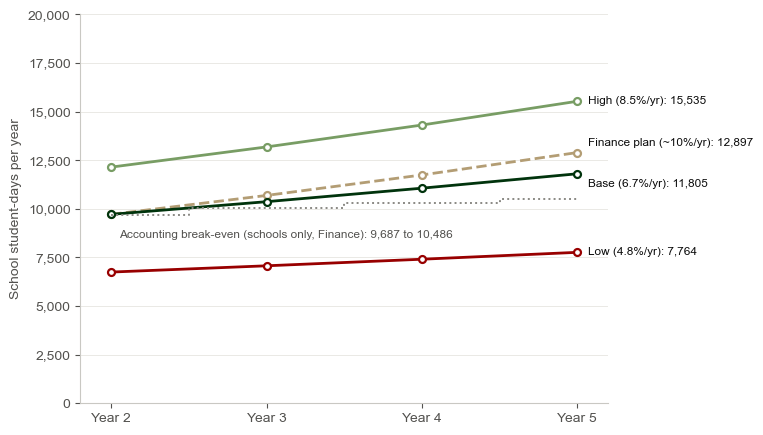

In [18]:
# ---- Fig 1: predicted student-days vs break-even
fig, ax = plt.subplots(figsize=(8, 4.8)); fig.subplots_adjust(top=0.96, bottom=0.15, left=0.10, right=0.76)
yrs = [2, 3, 4, 5]
for k in ('High', 'Finance plan', 'Base', 'Low'):
    v = R['scenarios'][k]['sd'][1:]
    ax.plot(yrs, v, color=COL[k], lw=2, ls='--' if k == 'Finance plan' else '-', marker='o', ms=5,
            mfc='#ffffff', mec=COL[k], mew=1.6)
    lab = {'Finance plan': "Finance plan (~10%/yr)", 'Base': f"Base ({R['grow']['Base']*100:.1f}%/yr)",
           'Low': f"Low ({R['grow']['Low']*100:.1f}%/yr)", 'High': f"High ({R['grow']['High']*100:.1f}%/yr)"}[k]
    dy = {'Finance plan': 7, 'Base': -7}.get(k, 0)
    ax.annotate(f"{lab}: {v[-1]:,.0f}", (5, v[-1]), xytext=(8, dy), textcoords='offset points', va='center', fontsize=8.5, color=INK)
be = [9687, 10035, 10318, 10486]
ax.step(yrs, be, where='mid', color='#8a8984', lw=1.4, ls=':')
ax.annotate("Accounting break-even (schools only, Finance): 9,687 to 10,486", (2.05, 8650), fontsize=8.5, color=INK2, va='center')
ax.set_xticks(yrs); ax.set_xticklabels([f"Year {y}" for y in yrs]); ax.set_xlim(1.8, 5.2)
ax.set_ylabel("School student-days per year"); ax.yaxis.set_major_formatter(FuncFormatter(lambda v, p: f"{v:,.0f}"))
ax.set_ylim(0, 20000); clean(ax)
title(fig, "Only the Base and High paths clear break-even by Year 5",
      "Predicted school student-days, Years 2-5. Year 1 is the set-up year (no programs).")
src(fig, "Source: team calculations; growth range from two comparable operators' financial statements (4.8%-8.5%, Crusader Union excluding\ncapital-campaign donations); break-even and plan from Finance's model. Low, Base and High: 50, 72 and 90 students.")
plt.show()

### Figure 4.2 Year 5 surplus by scenario
Year 5 operating surplus after depreciation in each scenario, against the $30,000 hurdle (dotted line).

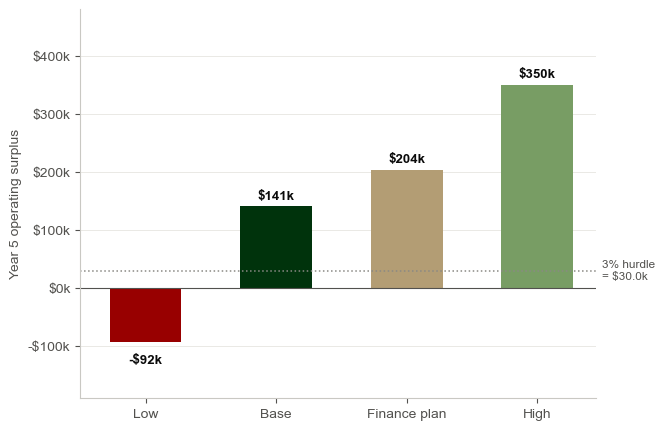

In [19]:
# ---- Fig 2: Y5 surplus by scenario
fig, ax = plt.subplots(figsize=(8.6, 4.8)); fig.subplots_adjust(top=0.96, bottom=0.15, left=0.10, right=0.70)
order = ['Low', 'Base', 'Finance plan', 'High']
vals = [R['scenarios'][k]['y5_surplus'] for k in order]
bars = ax.bar(range(4), vals, color=[COL[k] for k in order], width=0.55)
for i, v in enumerate(vals):
    ax.annotate(f"{'-' if v<0 else ''}${abs(v)/1000:,.0f}k", (i, v), xytext=(0, 5 if v >= 0 else -16), textcoords='offset points',
                ha='center', fontsize=9.5, color=INK, fontweight='bold')
ax.axhline(0, color=INK2, lw=0.8)
hh = R['sensitivity']['hurdle_conservative']
ax.axhline(hh, color='#8a8984', lw=1.1, ls=':')
ax.annotate(f"3% hurdle\n= ${hh/1000:,.1f}k", (3.45, hh), xytext=(4, 0), textcoords='offset points', fontsize=8.5, color=INK2, va='center')
ax.set_xticks(range(4)); ax.set_xticklabels(['Low', 'Base', 'Finance plan', 'High']); ax.set_xlim(-0.5, 3.45); ax.set_ylim(-190000, 480000)
ax.yaxis.set_major_formatter(usd); ax.set_ylabel("Year 5 operating surplus"); clean(ax)
title(fig, f"Year 5 surplus ranges from a ${abs(min(vals))/1000:,.0f}k loss to ${max(vals)/1000:,.0f}k across scenarios",
      "Operating surplus after depreciation, Year 5, against the 3% hurdle on the $1 million endowment.")
src(fig, "Source: team calculations using Finance's cost model (matches Finance's Year 5 surplus of $203,657 within $1). Dotted line: hurdle surplus.")
plt.show()

### Figure 4.3 One-at-a-time sensitivity
Year 5 surplus when each input moves to its adverse and favorable case around Finance's plan. Volume and price dominate.

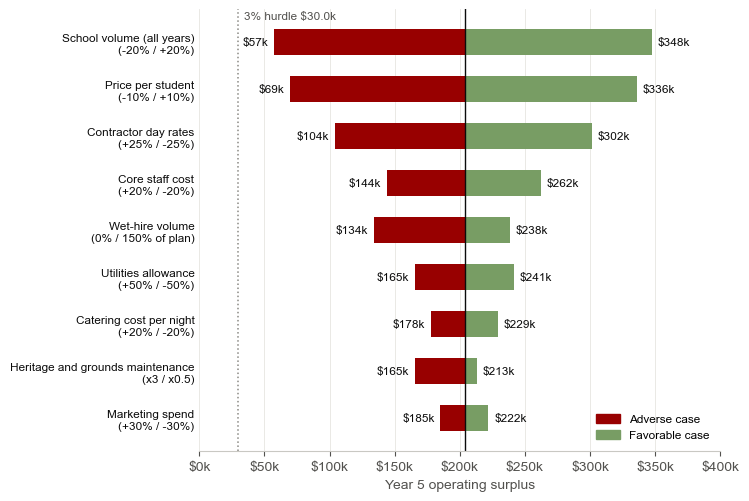

In [20]:
# ---- Fig 3: tornado
S = R['sensitivity']; rows = S['rows']; b = S['base_y5']
fig, ax = plt.subplots(figsize=(8.4, 5.2)); fig.subplots_adjust(top=0.97, bottom=0.12, left=0.33, right=0.95)
rows_r = rows[::-1]
for i, r in enumerate(rows_r):
    lo, hi = r['y5_low'], r['y5_high']
    adv, fav = min(lo, hi), max(lo, hi)
    ax.barh(i, adv - b, left=b, color='#980000', height=0.55)
    ax.barh(i, fav - b, left=b, color='#789D64', height=0.55)
    ax.annotate(f"${adv/1000:,.0f}k", (adv, i), xytext=(-4, 0), textcoords='offset points', ha='right', va='center', fontsize=8.5, color=INK)
    ax.annotate(f"${fav/1000:,.0f}k", (fav, i), xytext=(4, 0), textcoords='offset points', ha='left', va='center', fontsize=8.5, color=INK)
ax.set_yticks(range(len(rows_r))); ax.set_yticklabels([f"{r['name']}\n({r['note'].split(' (')[0]})" for r in rows_r], fontsize=8.5, color=INK)
ax.axvline(b, color=INK, lw=1); ax.set_xlim(0, 400000)
hh3 = S['hurdle_conservative']
ax.axvline(hh3, color='#8a8984', lw=1.1, ls=':')
ax.annotate(f"3% hurdle ${hh3/1000:,.1f}k", (hh3, len(rows_r) - 0.45), xytext=(4, 0), textcoords='offset points', fontsize=8.5, color=INK2, va='center')
ax.xaxis.set_major_formatter(usd); ax.set_xlabel("Year 5 operating surplus")
for s in ('top', 'right', 'left'): ax.spines[s].set_visible(False)
ax.tick_params(axis='y', length=0); ax.grid(axis='x', color='#e6e5e1', lw=0.6); ax.set_axisbelow(True)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color='#980000', label='Adverse case'), Patch(color='#789D64', label='Favorable case')],
          loc='lower right', frameon=False, fontsize=8.5)
title(fig, "Volume and price move Year 5 surplus most; no cost line alone takes it below zero",
      f"One-at-a-time sensitivity around the Finance plan (Year 5 surplus ${b/1000:,.0f}k).")
src(fig, "Source: team calculations. Ranges reflect the reliability ratings in Finance's model.")
plt.show()

### Figure 4.4 Monte Carlo distribution
Distribution of Year 5 surplus over 10,000 simulated futures (Case A), with the hurdle, Finance's plan, the median and the 5th and 95th percentiles.

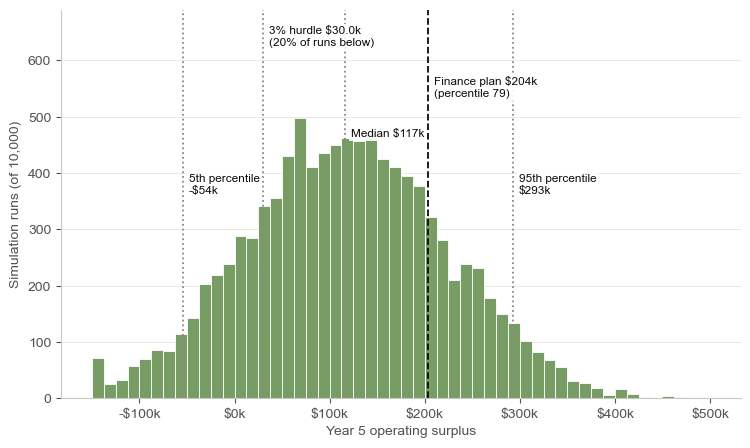

array([177983.18650775, 198703.9297962 , -55468.37998394, ...,
       126112.13235121, 173423.67154912, 148701.29833826])

In [21]:
# ---- Fig 4: Monte Carlo histogram
def hist(key, arr, fname, ttl, sub, xlab, marks, xlim, bins):
    y = arr
    fig, ax = plt.subplots(figsize=(8, 4.8)); fig.subplots_adjust(top=0.96, bottom=0.15, left=0.10, right=0.95)
    ax.hist(np.clip(y, *xlim), bins=bins, range=xlim, color='#789D64', edgecolor='#ffffff', lw=0.6)
    ax.set_ylim(0, ax.get_ylim()[1]*1.32); ymax = ax.get_ylim()[1]
    for (x, lab, dy) in marks:
        ax.axvline(x, color=INK if 'Finance' in lab else '#8a8984', lw=1.3, ls='--' if 'Finance' in lab else ':')
        ax.annotate(lab, (x, ymax*dy), xytext=(4, 0), textcoords='offset points', fontsize=8.5, color=INK, va='center', bbox=dict(fc='#ffffff', ec='none', alpha=0.92, pad=1.5))
    ax.xaxis.set_major_formatter(usd); ax.set_xlabel(xlab); ax.set_ylabel("Simulation runs (of 10,000)"); clean(ax)
    title(fig, ttl, sub); src(fig, "Source: team Monte Carlo (10,000 runs, seed 42, triangular inputs); tails above/below axis limits are bunched into the end bars.")
    plt.show(); return y
A = R['mc']['A_benchmark_growth']
hist('y5', MC_Y5['A_benchmark_growth'], None,
     f"About {A['p_y5_lt_hurdle_cons']*100:.0f}% of simulated futures fall below the 3% hurdle in Year 5",
     "Distribution of Year 5 operating surplus, benchmark-growth case.", "Year 5 operating surplus",
     [(S['hurdle_conservative'], f"3% hurdle $30.0k\n({A['p_y5_lt_hurdle_cons']*100:.0f}% of runs below)", 0.93),
      (b, f"Finance plan ${b/1000:,.0f}k\n(percentile {A['finance_plan_percentile_y5']:.0f})", 0.80),
      (A['y5']['50'], f"Median ${A['y5']['50']/1000:,.0f}k", 0.68),
      (A['y5']['5'], f"5th percentile\n-${abs(A['y5']['5'])/1000:,.0f}k", 0.55),
      (A['y5']['95'], f"95th percentile\n${A['y5']['95']/1000:,.0f}k", 0.55)], (-150000, 500000), 52)

### Figure 4.5 Comparators and the effect of growth and launch size
Left: the three growth observations and the scale of each operator against Hillview (an excerpt of the comparators workings). Right: Year 5 school student-days when only growth varies, or only launch size varies, with Base otherwise. Growth moves Year 5 volume by about 1,250 student-days; the launch moves it by about 6,550.

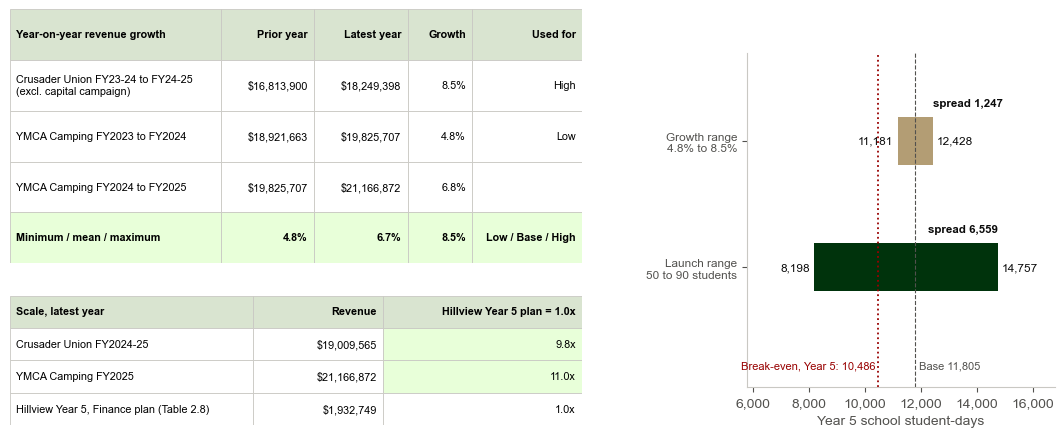

In [22]:
HDR, HL, GRID = '#D9E4D0', '#E8FFD9', '#c9c8c3'
def sheet(ax, rows, colw, y=0, rowh=1.0, hdr=1, hl=(), cellhl=(), bold=(), fs=8.2):
    """Draw a small spreadsheet-style table. Returns the y position after the last row."""
    x_edges = np.concatenate([[0], np.cumsum(colw)]); align = ['left'] + ['right'] * (len(colw) - 1)
    for i, row in enumerate(rows):
        for j, c in enumerate(row[:len(colw)]):
            fc = HDR if i < hdr else (HL if (i in hl or (i, j) in cellhl) else '#ffffff')
            ax.add_patch(Rectangle((x_edges[j], y), colw[j], rowh, fc=fc, ec=GRID, lw=0.6))
            if not c: continue
            ha = align[j]; px = x_edges[j] + (0.08 if ha == 'left' else colw[j] - 0.08)
            ax.text(px, y + rowh / 2, str(c), ha=ha, va='center', fontsize=fs, fontweight='bold' if (i < hdr or i in bold) else 'normal')
        y += rowh
    return y

fig = plt.figure(figsize=(11, 5.4))
ax = fig.add_axes([0.03, 0.40, 0.52, 0.47]); ax.set_axis_off()
rows = [["Year-on-year revenue growth", "Prior year", "Latest year", "Growth", "Used for"],
        ["Crusader Union FY23-24 to FY24-25\n(excl. capital campaign)", "$16,813,900", "$18,249,398", f"{GROWTH_OBS['Crusader Union FY23/24-24/25 (excl. capital campaign)']*100:.1f}%", "High"],
        ["YMCA Camping FY2023 to FY2024", "$18,921,663", "$19,825,707", f"{GROWTH_OBS['YMCA Camping FY23-24']*100:.1f}%", "Low"],
        ["YMCA Camping FY2024 to FY2025", "$19,825,707", "$21,166,872", f"{GROWTH_OBS['YMCA Camping FY24-25']*100:.1f}%", ""],
        ["Minimum / mean / maximum", f"{g_low*100:.1f}%", f"{g_mean*100:.1f}%", f"{g_high*100:.1f}%", "Low / Base / High"]]
yb = sheet(ax, rows, [2.6, 1.15, 1.15, 0.8, 1.35], hl=(4,), bold=(4,), fs=7.8); ax.set_ylim(yb, 0); ax.set_xlim(0, 7.05)
ax2 = fig.add_axes([0.03, 0.10, 0.52, 0.24]); ax2.set_axis_off()
rows2 = [["Scale, latest year", "Revenue", "Hillview Year 5 plan = 1.0x"],
         ["Crusader Union FY2024-25", "$19,009,565", "9.8x"],
         ["YMCA Camping FY2025", "$21,166,872", "11.0x"],
         ["Hillview Year 5, Finance plan (Table 2.8)", "$1,932,749", "1.0x"]]
yb2 = sheet(ax2, rows2, [3.0, 1.6, 2.45], fs=7.8, cellhl=((1, 2), (2, 2))); ax2.set_ylim(yb2, 0); ax2.set_xlim(0, 7.05)
axr = fig.add_axes([0.70, 0.17, 0.28, 0.62])
def y5vol(l, g): return PLAN_SD[1] * l * (1 + g) ** 3          # Year 5 school student-days for a launch factor l and growth g
gr = (y5vol(1, g_low), y5vol(1, g_high)); lr = (y5vol(50/72, g_mean), y5vol(90/72, g_mean)); base_v = y5vol(1, g_mean)
for i, (a, b_, c) in enumerate([(gr[0], gr[1], '#B39D74'), (lr[0], lr[1], '#00330C')]):
    axr.barh(i, b_ - a, left=a, height=0.38, color=c)
    axr.text(a - 150, i, f"{a:,.0f}", ha='right', va='center', fontsize=8.5, color=INK)
    axr.text(b_ + 150, i, f"{b_:,.0f}", ha='left', va='center', fontsize=8.5, color=INK)
    axr.text(b_, i - 0.30, f"spread {b_ - a:,.0f}", ha='right' if i == 1 else 'left', va='center', fontsize=8.3, color=INK, fontweight='bold')
axr.axvline(BE_ACC[4], color='#980000', lw=1.3, ls=':'); axr.text(BE_ACC[4] - 90, 1.78, f"Break-even, Year 5: {BE_ACC[4]:,}", ha='right', va='center', fontsize=8, color='#980000')
axr.axvline(base_v, color=INK2, lw=0.8, ls='--'); axr.text(base_v + 120, 1.78, f"Base {base_v:,.0f}", fontsize=8, color=INK2, va='center')
axr.set_yticks([0, 1]); axr.set_yticklabels(["Growth range\n4.8% to 8.5%", "Launch range\n50 to 90 students"], fontsize=8.5)
axr.set_xlim(5800, 16800); axr.set_ylim(1.95, -0.7)
axr.xaxis.set_major_formatter(FuncFormatter(lambda v, p: f"{v:,.0f}")); axr.set_xlabel("Year 5 school student-days")
for s_ in ('top', 'right'): axr.spines[s_].set_visible(False)
plt.show()

### Figure 4.6 Cost of access and heritage commitments
Left: median simulated Year 5 surplus. Right: share of simulated runs below the $30,000 hurdle. The discount is offered from the start (red), only once Year 2 bookings reach 9,700 (green), or from the start with heritage maintenance doubled (sand). The star marks the recommendation: 10% access, only once the trigger is met.

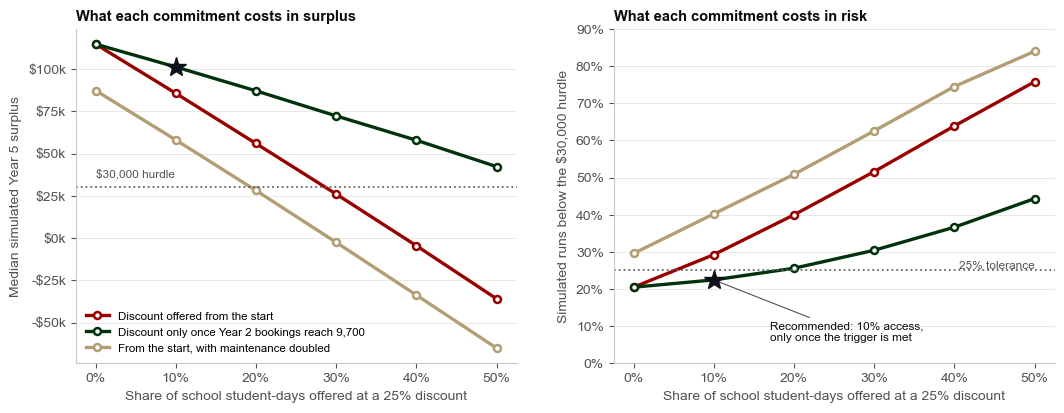

In [23]:
COL6 = {'uncond': '#980000', 'cond': '#00330C', 'uncond_m2': '#B39D74'}
LAB = {'uncond': 'Discount offered from the start', 'cond': 'Discount only once Year 2 bookings reach 9,700', 'uncond_m2': 'From the start, with maintenance doubled'}
fig, axs = plt.subplots(1, 2, figsize=(11, 4.4)); fig.subplots_adjust(top=0.93, bottom=0.17, left=0.08, right=0.97, wspace=0.22)
for ax in axs:
    for s_ in ('top', 'right'): ax.spines[s_].set_visible(False)
    ax.grid(axis='y', color='#e6e5e1', lw=0.6); ax.set_axisbelow(True)
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, p: f"{v*100:.0f}%")); ax.set_xlabel("Share of school student-days offered at a 25% discount")
for k in ('uncond', 'cond', 'uncond_m2'):
    xs = [r['a'] for r in out['curves'][k]]
    for ax, f in ((axs[0], 'med'), (axs[1], 'p_lt30')):
        ax.plot(xs, [r[f] for r in out['curves'][k]], color=COL6[k], lw=2.4, marker='o', ms=5, mfc='#ffffff', mew=1.8, label=LAB[k])
axs[0].axhline(30000, color='#666666', lw=1.3, ls=':'); axs[0].text(0.0, 36000, "$30,000 hurdle", ha='left', fontsize=8.5, color=INK2)
axs[0].yaxis.set_major_formatter(usd); axs[0].set_ylabel("Median simulated Year 5 surplus")
axs[0].set_title("What each commitment costs in surplus", loc='left', fontsize=10.5, fontweight='bold', color=INK)
axs[1].axhline(0.25, color='#666666', lw=1.3, ls=':'); axs[1].text(0.5, 0.255, "25% tolerance", ha='right', fontsize=8.5, color=INK2)
axs[1].yaxis.set_major_formatter(FuncFormatter(lambda v, p: f"{v*100:.0f}%")); axs[1].set_ylim(0, 0.9)
axs[1].set_ylabel("Simulated runs below the $30,000 hurdle")
axs[1].set_title("What each commitment costs in risk", loc='left', fontsize=10.5, fontweight='bold', color=INK)
rc = out['curves']['cond'][1]
axs[0].plot([0.1], [rc['med']], marker='*', ms=15, color='#0E101A', zorder=5, ls=''); axs[1].plot([0.1], [rc['p_lt30']], marker='*', ms=15, color='#0E101A', zorder=5, ls='')
axs[1].annotate("Recommended: 10% access,\nonly once the trigger is met", (0.1, rc['p_lt30']), xytext=(0.17, 0.06), fontsize=8.5, color=INK, arrowprops=dict(arrowstyle='-', color=INK2, lw=0.8))
axs[0].legend(frameon=False, fontsize=8.3, loc='lower left')
plt.show()